# 02 · Modeling

Protocol: hyper-parameters and probability thresholds are chosen on **VALIDATION** (fit on
TRAIN), then the chosen configuration is refit on TRAIN+VALIDATION and evaluated once on
**TEST** (2024 → today). Models: hand rules, DecisionTree, RandomForest (lecture) +
XGBoost, LightGBM, LogisticRegression (new) + an RF/XGB/LGBM probability ensemble.


In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3})
from driftrev import config, store, artifacts, dataset, features, models, simulate, analysis, pipeline
print("data dir:", config.DATA_DIR)

data dir: /Users/mac/Documents/New project/stock-data-analysis/project/data


In [2]:
events = store.read_table("events"); ml, feats = dataset.prepare(events)
ml.groupby("split")[dataset.TARGET].agg(["size", "mean"])

,size,mean
split,,
test,46831,0.399226
train,99735,0.361458
validation,30236,0.387650


### Hyper-parameter tuning table (validation)

In [3]:
tuning = pd.read_parquet(config.ARTIFACTS_DIR / "tuning.parquet")
tuning.sort_values(["model", "val_prec_top10"], ascending=[True, False]).groupby("model").head(3)

,model,params,val_auc,val_prec_top10,val_prec_top20,val_base_rate,fit_seconds
17,lgbm,"{""n_estimators"": 600, ""num_leaves"": 31, ""learn...",0.508611,0.357923,0.369605,0.38765,6.3
16,lgbm,"{""n_estimators"": 600, ""num_leaves"": 15, ""learn...",0.511574,0.347006,0.357202,0.38765,4.4
14,lgbm,"{""n_estimators"": 300, ""num_leaves"": 15, ""learn...",0.512782,0.341714,0.353233,0.38765,2.5
18,logreg,"{""C"": 0.01}",0.549544,0.597420,0.514305,0.38765,1.8
19,logreg,"{""C"": 0.1}",0.548641,0.590804,0.511989,0.38765,3.4
20,logreg,"{""C"": 1.0}",0.548938,0.588157,0.511989,0.38765,4.3
6,rf,"{""n_estimators"": 300, ""max_depth"": 8, ""min_sam...",0.547893,0.487264,0.473954,0.38765,15.2
8,rf,"{""n_estimators"": 300, ""max_depth"": 12, ""min_sa...",0.543426,0.470063,0.461882,0.38765,23.3
9,rf,"{""n_estimators"": 300, ""max_depth"": 12, ""min_sa...",0.545622,0.469732,0.468331,0.38765,22.9
2,tree,"{""max_depth"": 5, ""min_samples_leaf"": 50}",0.508953,0.407873,0.376385,0.38765,3.5


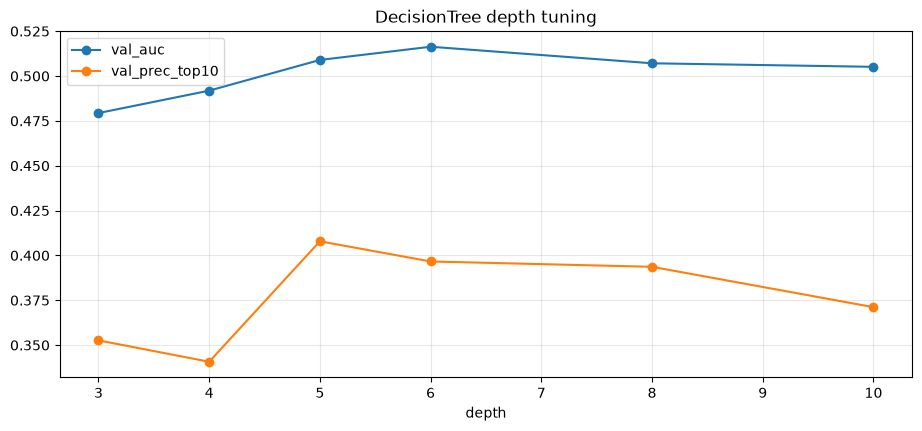

In [4]:
tree = tuning[tuning.model == "tree"].copy(); tree["depth"] = tree.params.map(lambda p: json.loads(p)["max_depth"])
tree.plot(x="depth", y=["val_auc", "val_prec_top10"], marker="o", title="DecisionTree depth tuning"); plt.show()

### Model comparison (validation vs test AUC) and the production choice

In [5]:
metrics = artifacts.load_metrics()
print("production:", metrics["model"]["name"], "| threshold", metrics["model"]["threshold"])
pd.DataFrame(metrics["models"])[["name", "val_auc", "test_auc", "threshold"]].sort_values("val_auc", ascending=False)

production: rf | threshold 0.47


,name,val_auc,test_auc,threshold
1,logreg,0.549544,0.531420,0.71
2,rf,0.547893,0.540790,0.47
5,ensemble,0.515723,0.539325,0.47
4,xgb,0.509269,0.535047,0.48
3,tree,0.508953,0.519073,0.62
0,lgbm,0.508611,0.536793,0.49


### Decision rules on TEST (hand rules vs models vs custom rules)

In [6]:
artifacts.load_frame("pred_eval.parquet")

,prediction,n_trades,share,precision,avg_growth_10d,base_rate
0,pred4_logreg_best_rule_71,53,0.001158,0.566038,1.065802,0.399226
1,pred9_ensemble_top1_daily,423,0.009246,0.508274,1.032367,0.399226
2,pred5_rf_best_rule_47,992,0.021683,0.491935,1.020457,0.399226
3,pred8_ensemble_best_rule_47,7204,0.157461,0.460161,1.017874,0.399226
4,pred3_lgbm_best_rule_49,6649,0.145330,0.456309,1.017307,0.399226
5,pred7_xgb_best_rule_48,11260,0.246115,0.440675,1.014624,0.399226
6,pred1_manual_panic_no_damage,1587,0.034688,0.434152,1.011451,0.399226
7,pred6_tree_best_rule_62,22644,0.494940,0.419493,1.008145,0.399226
8,pred2_manual_all_events,45751,1.000000,0.399226,1.006955,0.399226
9,pred_armA_momentum_breakout,28195,0.616271,0.396276,1.006869,0.399226


### Feature importance

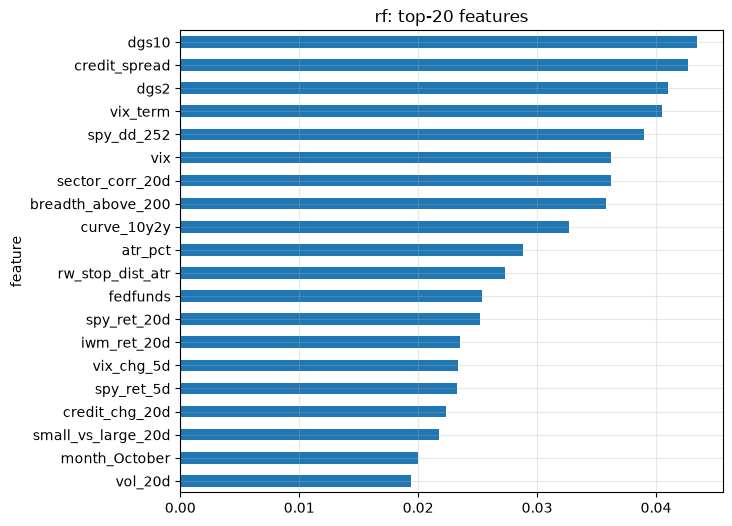

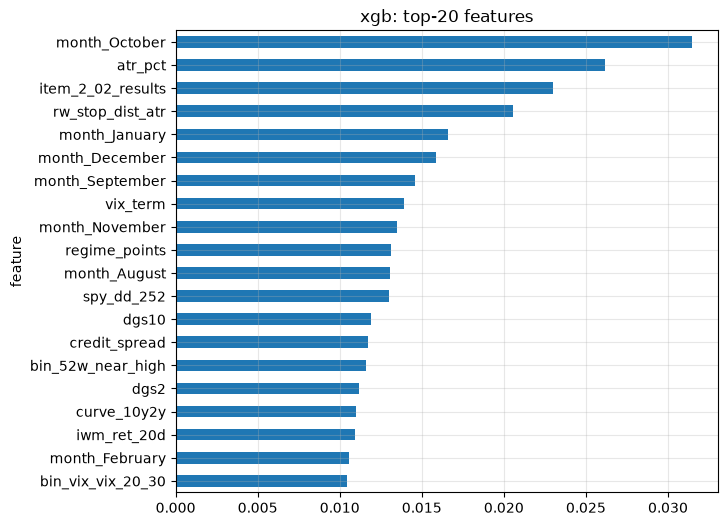

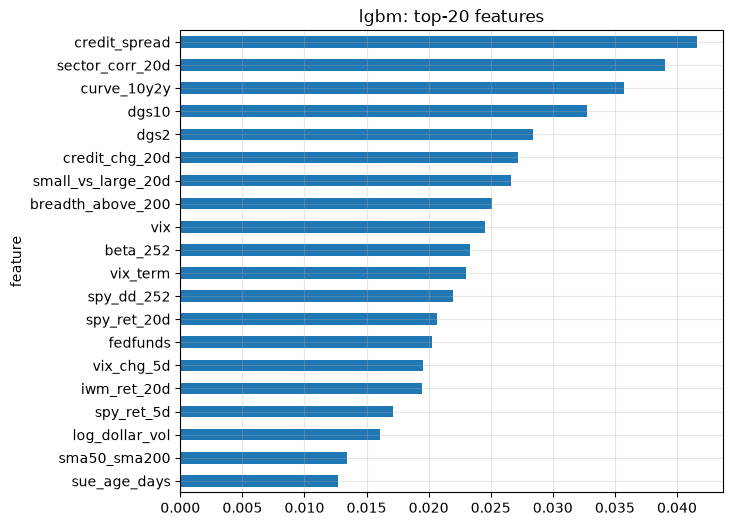

In [7]:
imp = artifacts.load_frame("importance")
for m in ["rf", "xgb", "lgbm"]:
    s = imp[imp.model == m].head(20).set_index("feature")["importance"][::-1]
    s.plot(kind="barh", figsize=(7, 6), title=f"{m}: top-20 features"); plt.show()

### Calibration of the production probabilities on TEST

In [8]:
cal = artifacts.load_frame("calibration.parquet"); cal

,bucket,mean_prob,hit_rate,avg_growth,n
0,"(0.228, 0.315]",0.292646,0.347247,1.004966,4576
1,"(0.315, 0.341]",0.328946,0.356721,1.001868,4575
2,"(0.341, 0.359]",0.350820,0.368743,1.003427,4575
3,"(0.359, 0.374]",0.366812,0.399781,1.004538,4575
4,"(0.374, 0.385]",0.379512,0.395847,1.004365,4575
5,"(0.385, 0.397]",0.390993,0.397814,1.002245,4575
6,"(0.397, 0.408]",0.402512,0.398689,1.003069,4575
7,"(0.408, 0.421]",0.414598,0.410055,1.009670,4575
8,"(0.421, 0.437]",0.428534,0.440656,1.016475,4575
9,"(0.437, 0.548]",0.458058,0.476721,1.018931,4575
